# Datasets and the atlas: browse, load, fetch

U-Chrom's datasets come from three places: the **atlas** (public stores that open over HTTP), **datasets with a
loader** (built once from their original files) and the **original files** themselves.  This tutorial goes
through all three with `uchrom.datasets`:

1. browse the atlas — what is there, for which organism, with which modalities;
2. load a store over HTTP and read one cell of it: its 3-D structure and its contact map;
3. fetch the store as one file for offline work, and load the local copy;
4. datasets with a loader, and original files.

- **Data**: the atlas store `stevens2017_mesc` (Stevens et al. 2017, *Nature* 544:59: 8 haploid mESCs, 100 kb
  structures, 26 MB), the loader dataset `takei2021_mesc` and the Takei 2021 cell table (4DN).
- **Runtime**: about a minute on a laptop (a 26 MB download).

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import uchrom.datasets as ds
from chromdata import catalog
from uchrom.fea import contact_matrix

plt.rcParams["figure.dpi"] = 90
T0 = time.time()
DATA = ds.data_dir()
print("data directory:", str(DATA).replace(str(Path.home()), "~"))     # $UCHROM_DATA, else ~/.cache/uchrom

data directory: ~/.cache/uchrom


## 1. Browse the atlas

`ds.list_atlas()` reads the atlas catalog: one row per store, with what it is, how many cells (spots, for
spatial data) it holds, its modalities, its size and its one-file download.  The same datasets are on the
atlas page, [uchrom-atlas.u-science.org](https://uchrom-atlas.u-science.org), and open in the hosted web
browser, [uchrom-browser.u-science.org](https://uchrom-browser.u-science.org).

In [2]:
atlas = ds.list_atlas()
print(f"{len(atlas)} stores, {atlas['n_cells'].sum():,} cells / spots, {atlas['size_mb'].sum() / 1e3:.1f} GB")
atlas[["title", "organism", "assembly", "n_cells", "size_mb", "downloaded"]].sort_values("n_cells")

22 stores, 315,516 cells / spots, 25.6 GB


,title,organism,assembly,n_cells,size_mb,downloaded
id,,,,,,
stevens2017_mesc,Single-cell Hi-C and 3-D structures: haploid m...,Mus musculus,mm10,8,25.8,False
unic_mouse,Uni-C: mouse circulating tumour cells and MC38,Mus musculus,mm10,20,270.9,False
unic_human,Uni-C: human cell lines and circulating tumour...,Homo sapiens,hg19,23,681.2,False
hires_brain,HiRES: adult mouse brain,Mus musculus,mm10,399,260.9,False
gageseq_human_bm_cd34,GAGE-seq: human bone marrow CD34+,Homo sapiens,hg38,1445,319.0,False
takei2025_cerebellum,DNA seqFISH+: adult mouse cerebellum,Mus musculus,mm10,1799,2050.7,False
gageseq_mouse_cortex,GAGE-seq: mouse cortex,Mus musculus,mm10,3296,484.9,False
atac_hic_mouse_brain,Spatial ATAC-Hi-C: mouse brain,Mus musculus,mm10,4290,389.7,False
schicar_mouse_cortex,"scHiCAR: mouse frontal cortex, contacts, acces...",Mus musculus,mm10,5313,262.8,False


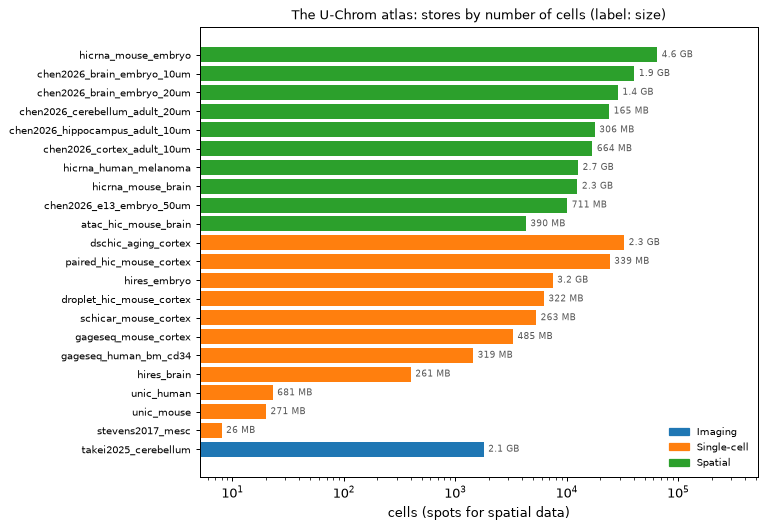

In [3]:
# what kind of data each store holds: the catalog's studies say it (spatial, single-cell, imaging)
cat = catalog.fetch_catalog(catalog.DEFAULT_ATLAS)
kind = {s["id"]: s.get("category", "") for s in cat["studies"]}
atlas["kind"] = atlas["study"].map(kind)
order = atlas.sort_values(["kind", "n_cells"])
colors = {k: f"C{i}" for i, k in enumerate(sorted(order["kind"].unique()))}

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(range(len(order)), order["n_cells"], color=[colors[k] for k in order["kind"]])
ax.set_yticks(range(len(order)), order.index, fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("cells (spots for spatial data)")
for i, (n, mb) in enumerate(zip(order["n_cells"], order["size_mb"])):
    ax.text(n * 1.1, i, f"{mb / 1e3:.1f} GB" if mb >= 1000 else f"{mb:.0f} MB", va="center", fontsize=7, color="0.35")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors),
          loc="lower right", fontsize=8, frameon=False)
ax.set_title("The U-Chrom atlas: stores by number of cells (label: size)", fontsize=10)
ax.set_xlim(right=order["n_cells"].max() * 8)
plt.show()

Selecting by modality: e.g. the stores with 3-D structures (imaging, or structures reconstructed from
single-cell Hi-C).

In [4]:
atlas[atlas["modalities"].map(lambda m: "3-D coordinates" in m)][["title", "n_cells", "modalities"]]

,title,n_cells,modalities
id,,,
stevens2017_mesc,Single-cell Hi-C and 3-D structures: haploid m...,8,"[Hi-C per cell, Hi-C bulk, 3-D coordinates]"
hires_brain,HiRES: adult mouse brain,399,"[Hi-C per cell, Hi-C bulk, RNA, 3-D coordinate..."
hires_embryo,"HiRES: mouse embryo, E7.0 to E9.5",7469,"[Hi-C per cell, Hi-C bulk, RNA, 3-D coordinate..."
takei2025_cerebellum,DNA seqFISH+: adult mouse cerebellum,1799,"[signals per spot, 3-D coordinates, embeddings]"


## 2. Load a store over HTTP

`ds.load(id)` opens an atlas store **backed**: the small tables are read at once, everything else when it is
asked for — one cell, one chromosome, one level of a contact map — with HTTP range requests.  Nothing is
downloaded up front.

In [5]:
t = time.time()
cd = ds.load("stevens2017_mesc")
print(f"opened in {time.time() - t:.1f} s\n")
print(cd)
print("\n", cd.uns["coordinate_status"])
cd.cells

opened in 2.1 s

ChromData (backed: stevens2017_mesc.chromdata.zarr): n_spots=205706, n_traces=160, n_cells=8, n_bins=25734
  spots:   ['chrom', 'start', 'end', 'trace_id', 'cell_id', 'bin_id']
  cells:   ['gsm', 'n_contacts', 'cell_type'] (8 cells)
  layers:  ['model_2', 'model_3', 'model_4', 'model_5', 'model_6', 'model_7', 'model_8', 'model_9', 'model_10']
  uns:     ['genome_assembly', 'xyz_unit', 'source', 'coordinate_status', 'linked_cool', 'linked_scool']

 the authors' NucDynamics structures, 100 kb particles: model 1 in coords, models 2-10 in layers


,gsm,n_contacts,cell_type
cell_id,,,
Cell_1,GSM2219497,111838,haploid mESC (G1)
Cell_2,GSM2219498,79569,haploid mESC (G1)
Cell_3,GSM2219499,31507,haploid mESC (G1)
Cell_4,GSM2219500,88866,haploid mESC (G1)
Cell_5,GSM2219501,69273,haploid mESC (G1)
Cell_6,GSM2219502,72323,haploid mESC (G1)
Cell_7,GSM2219503,53119,haploid mESC (G1)
Cell_8,GSM2219504,40217,haploid mESC (G1)


The store also holds contact maps, embedded: the merged map of all cells (`bulk`: 100 kb, 500 kb, 1 Mb)
and one map per cell (`per_cell`, 1 Mb).  Reading one cell gives an in-memory `ChromData` of that cell's
structure; the maps are read the same way, one level or one cell at a time.

In [6]:
t = time.time()
cell = cd.get_cell("Cell_1")                                       # 8 cells x 20 chromosomes x 100 kb particles
print(f"Cell_1: {cell.n_spots:,} particles, {cell.n_traces} chromosomes, read in {time.time() - t:.1f} s")

t = time.time()
bins, bulk = contact_matrix(cd, "bulk", chrom="chr2", resolution=1_000_000)   # merged map, one level exported
one = cd.load_linked_scool(key="per_cell", cell="Cell_1")                    # one cell's map (a cooler)
single = one.matrix(balance=False).fetch("chr2")
print(f"chr2 at 1 Mb: merged map {bulk.shape}, Cell_1 {int(np.nansum(np.triu(single)))} contacts, "
      f"read in {time.time() - t:.1f} s")

Cell_1: 25,724 particles, 20 chromosomes, read in 6.2 s


chr2 at 1 Mb: merged map (183, 183), Cell_1 7676 contacts, read in 8.4 s


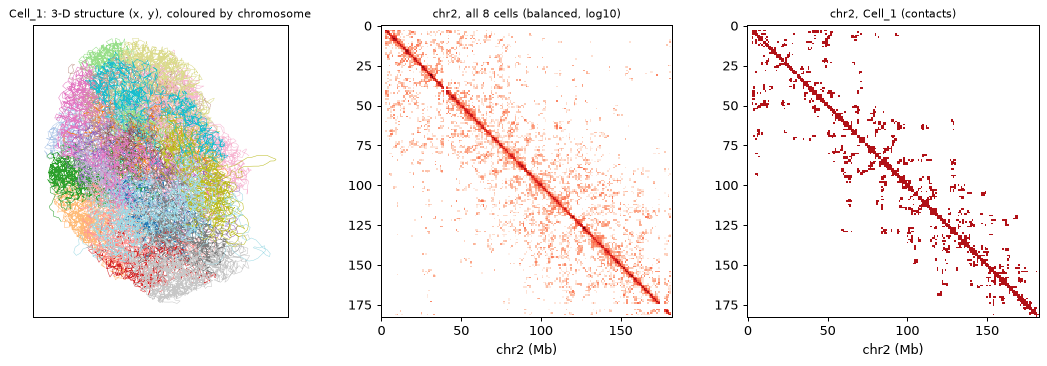

In [7]:
spots = cell.spots_with_loci()
xyz = cell.coords
chroms = spots["chrom"].astype(str).to_numpy()
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 3, 1)
for k, c in enumerate(pd.unique(chroms)):
    s = chroms == c
    ax.plot(xyz[s, 0], xyz[s, 1], lw=0.4, color=plt.cm.tab20(k % 20))
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Cell_1: 3-D structure (x, y), coloured by chromosome", fontsize=9)
for j, (m, title) in enumerate(((bulk, "chr2, all 8 cells (balanced, log10)"), (single, "chr2, Cell_1 (contacts)")), 2):
    ax = fig.add_subplot(1, 3, j)
    img = np.log10(np.where(m > 0, m, np.nan)) if j == 2 else np.where(single > 0, 1.0, np.nan)
    ax.imshow(img, cmap="Reds", interpolation="none", **({} if j == 2 else {"vmin": 0, "vmax": 1.2}))
    ax.set_title(title, fontsize=9); ax.set_xlabel("chr2 (Mb)")
plt.tight_layout(); plt.show()

## 3. Fetch a local copy for offline work

`ds.fetch(id)` downloads the store's one-file copy (`.cdz`: the same files, in one uncompressed zip) into the
data directory, once.  From then on `ds.load(id)` opens the local copy — the same `ChromData`, read from
disk.  `ds.atlas(id, local=False)` still reads the remote store.

In [8]:
t = time.time()
path = ds.fetch("stevens2017_mesc", verbose=False)
print(f"<data directory>/{path.relative_to(DATA)} ({path.stat().st_size / 1e6:.1f} MB) in {time.time() - t:.1f} s")
print("downloaded:", ds.list_atlas().loc["stevens2017_mesc", "downloaded"])

local = ds.load("stevens2017_mesc")
remote = ds.atlas("stevens2017_mesc", local=False)
for name, obj in (("local copy", local), ("over HTTP", remote)):
    t = time.time()
    c = obj.get_cell("Cell_2")
    print(f"{name:10s}: Cell_2 with {c.n_spots:,} particles in {time.time() - t:.2f} s")
assert np.allclose(local.get_cell("Cell_2").coords, remote.get_cell("Cell_2").coords)

<data directory>/atlas/stevens2017_mesc.cdz (25.6 MB) in 1.9 s


downloaded: True


local copy: Cell_2 with 25,719 particles in 0.02 s


over HTTP : Cell_2 with 25,719 particles in 5.77 s


## 4. Datasets with a loader, and original files

`ds.list_datasets()` is the registry of everything U-Chrom knows how to get: the column `load` marks the
datasets that come as a `ChromData` (built once from the original files by a loader, then read from the data
directory), the others are files — raw formats, reference genomes, annotations, published calls.

In [9]:
reg = ds.list_datasets()
print(f"{len(reg)} entries, {int(reg['load'].sum())} with a loader")
reg[reg["load"]][["size_mb", "description"]]

52 entries, 10 with a loader


,size_mb,description
name,,
bintu_imr90,2.0,Bintu 2018 IMR90 chr21 chromatin tracing
su2020_chr21,262.0,Su 2020 IMR90 chr21 chromatin tracing + binned...
tan2018_gm12878,700.0,"Tan 2018 Dip-C GM12878, 17 cells: hickit imput..."
wu2025_scmicroc,3100.0,"Wu 2025 scMicro-C GM12878, 12 deepest cells: h..."
kim2020_scihic,128.0,"Kim 2020 sci-Hi-C, H1 ES + HFF (Noble lab)"
huang2021_sox2,7.0,Huang 2021 mESC Sox2 tracing with missing loci...
rao2014_imr90_chr21,4.0,"Rao 2014 IMR90 Hi-C chr21 at 5 kb, sliced over..."
takei2021_mesc,NaN,Takei 2021 mESC DNA seqFISH+ (4DN FOF-CT): 201...
bintu_imr90_hg19,NaN,Bintu 2018 IMR90 chr21 tracing on hg19 (20.0-2...


In [10]:
t = time.time()
tracing = ds.load("takei2021_mesc")                 # built on first use, read from the data directory afterwards
print(f"takei2021_mesc in {time.time() - t:.1f} s: {tracing.n_cells} cells, {tracing.n_traces:,} traces, "
      f"{tracing.n_spots:,} spots")

ds.fetch("takei_tables", verbose=False)             # original files: the 4DN cell and RNA tables (md5-checked)
for f in ds.files("takei_tables"):
    print(f"<data directory>/{f.relative_to(DATA)}: {f.stat().st_size / 1e3:.0f} KB")
print("read by: ChromData.from_fofct(core, cell_table=..., rna_table=...) — the FOF-CT import tutorial")

takei2021_mesc in 0.0 s: 201 cells, 8,285 traces, 316,995 spots
<data directory>/4DNFIFINA2U9.csv: 58 KB
<data directory>/4DNFIJ52NVDV.csv: 219 KB
read by: ChromData.from_fofct(core, cell_table=..., rna_table=...) — the FOF-CT import tutorial


## Where it all goes

Downloads and built datasets live in the data directory, `$UCHROM_DATA` (else `~/.cache/uchrom`); set it to put
large data elsewhere (a cluster's scratch space).  The same operations from a shell:

```bash
python -m uchrom.datasets atlas                       # the atlas, with what is downloaded
python -m uchrom.datasets fetch stevens2017_mesc      # an atlas store (.cdz)
python -m uchrom.datasets list                        # the registry
python -m uchrom.datasets load takei2021_mesc         # build a loader dataset ahead
python -m uchrom.datasets fetch takei hg19_chr21      # original files
```

Where every dataset comes from — study, accession, licence, size — is in the
[data sources](../reference/data_sources).

In [11]:
print(f"total run time {time.time() - T0:.0f} s")

total run time 27 s
